
# Hypothesis test 3: A/B-style comparison, life expectancy before vs after 2000

**Question:** is average life expectancy different from 2000 onward than before 2000?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

# I load the joined table

df = pd.read_csv(r"C:\Users\admin\Desktop\Captoneproject-pydata\data\clean_joined.csv")
print("Rows:", len(df))

Rows: 10429


In [2]:
# HYPOTHESIS B4 TEST

print("H0: the average life expectancy was the same before 2000 and from 2000 onward.")
print("H1: the average life expectancy was different between the two periods.")
print("I will reject H0 if the p-value is below 0.05.")

H0: the average life expectancy was the same before 2000 and from 2000 onward.
H1: the average life expectancy was different between the two periods.
I will reject H0 if the p-value is below 0.05.


In [10]:
# the two groups
before = df[df["period"] == "Before 2000"]["life_exp"]
after = df[df["period"] == "2000 and after"]["life_exp"]
summary = df.groupby("period")["life_exp"].agg(["count", "mean", "median", "std"]).round(2)
display(summary.reindex(["Before 2000", "2000 and after"]))

,count,mean,median,std
period,,,,
Before 2000,6692,60.25,62.28,11.76
2000 and after,3737,70.09,72.12,9.09


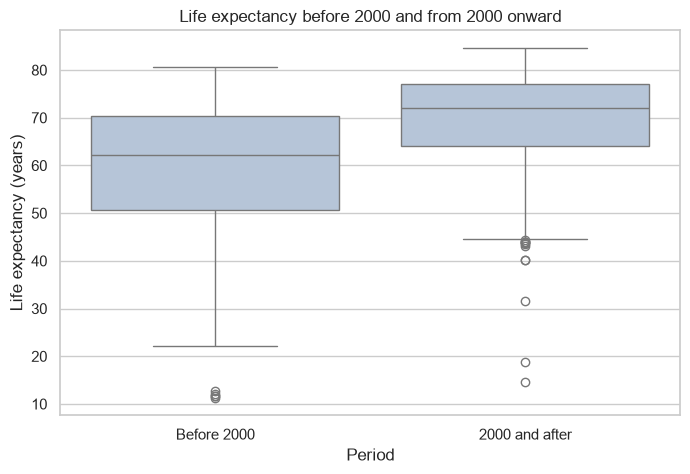

In [5]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="period", y="life_exp", order=["Before 2000", "2000 and after"], color="lightsteelblue")
plt.title("Life expectancy before 2000 and from 2000 onward")
plt.xlabel("Period")
plt.ylabel("Life expectancy (years)")
plt.show()

In [11]:
# Welch t-test: does not assume the two groups have equal spreads
t_stat, p_value = stats.ttest_ind(before, after, equal_var=False)
print(f"Welch t = {t_stat:.2f}")
print("p-value:", "less than 0.001" if p_value < 0.001 else round(p_value, 3))

# difference in means with a 95% confidence interval (Welch)
diff = after.mean() - before.mean()
se = np.sqrt(before.var() / len(before) + after.var() / len(after))
dof = se**4 / ((before.var() / len(before))**2 / (len(before) - 1) + (after.var() / len(after))**2 / (len(after) - 1))
t_crit = stats.t.ppf(0.975, dof)
print(f"Difference (after minus before): {diff:.2f} years, 95% CI {diff - t_crit * se:.2f} to {diff + t_crit * se:.2f}")

Welch t = -47.59
p-value: less than 0.001
Difference (after minus before): 9.84 years, 95% CI 9.44 to 10.25


In [12]:
# the same countries appear in both periods, so I also compare each country with itself
cm = df.groupby(["Entity", "period"])["life_exp"].mean().unstack().dropna()
gain = cm["2000 and after"] - cm["Before 2000"]
t_paired, p_paired = stats.ttest_rel(cm["2000 and after"], cm["Before 2000"])
print("Countries with both periods:", len(cm))
print(f"Average gain per country: {gain.mean():.2f} years")
print(f"Countries that improved: {int((gain > 0).sum())} of {len(cm)}")
print(f"Paired t = {t_paired:.2f}, p-value:", "less than 0.001" if p_paired < 0.001 else round(p_paired, 3))

Countries with both periods: 163
Average gain per country: 9.60 years
Countries that improved: 158 of 163
Paired t = 24.11, p-value: less than 0.001


## Result

**H0:** mean life expectancy is the same before 2000 and from 2000 onward. **H1:** it differs. **Test:** Welch two-sample t-test, because I compare the means of a continuous variable between two groups whose spreads may differ. Alpha = 0.05.

**Result:** t = -47.59, p < 0.001, so I reject H0. Mean life expectancy was 60.3 years before 2000 and 70.1 years from 2000 onward, a difference of 9.84 years (95% CI 9.44 to 10.25). Cohen's d = 0.90, a large effect.

**Country by country:** all 163 countries have data in both periods; 158 improved, with an average gain of 9.60 years (paired t = 24.11, p < 0.001).

**What the p-value does not mean:** it is not the probability that H0 is true, and it does not say how big the difference is. The difference and Cohen's d do that.

**Caveats:**
- This is "A/B-style", not a real experiment: the periods were not randomly assigned, so the test shows that life expectancy differs, not what caused the change.
- The same countries appear in both periods and in many years, so rows are not independent. The paired country check addresses this.
- The pre-2000 period covers 50 years and the later one 23, so "before" mixes very different decades.

In [8]:
# CHECKING OUT THE DIFFERENCE
difference = after.mean() - before.mean()
std_error = np.sqrt(before.var() / len(before) + after.var() / len(after))
low, high = difference - 1.96 * std_error, difference + 1.96 * std_error
pooled_std = np.sqrt(((len(before) - 1) * before.var() + (len(after) - 1) * after.var()) / (len(before) + len(after) - 2))
cohens_d = difference / pooled_std

print(f"Average life expectancy was {difference:.2f} years higher from 2000 onward")
print(f"95% confidence interval for the difference: {low:.2f} to {high:.2f} years")
print(f"Effect size (Cohen's d) = {cohens_d:.2f}")
print("Rough guide: 0.2 small, 0.5 medium, 0.8 large")

Average life expectancy was 9.84 years higher from 2000 onward
95% confidence interval for the difference: 9.44 to 10.25 years
Effect size (Cohen's d) = 0.90
Rough guide: 0.2 small, 0.5 medium, 0.8 large


In [9]:
# the same countries appear in both periods, so I compare each country with itself
country_means = df.groupby(["Entity", "period"])["life_exp"].mean().unstack().dropna()
country_diff = country_means["2000 and after"] - country_means["Before 2000"]
t_paired, p_paired = stats.ttest_rel(country_means["2000 and after"], country_means["Before 2000"])

print("Countries with data in both periods:", len(country_means))
print(f"Average gain per country: {country_diff.mean():.2f} years")
print("Countries with higher life expectancy from 2000:", (country_diff > 0).sum(), "of", len(country_diff))
print(f"Paired t statistic = {t_paired:.2f}, p-value", "< 0.001" if p_paired < 0.001 else round(p_paired, 3))

Countries with data in both periods: 163
Average gain per country: 9.60 years
Countries with higher life expectancy from 2000: 158 of 163
Paired t statistic = 24.11, p-value < 0.001


# H0: The average life expectancy was the same before 2000 and from 2000 onward.

H1: The average life expectancy was different between the two periods.

Significance level: 0.05

## Result

**H0:** mean life expectancy is the same before 2000 and from 2000 onward. **H1:** it differs. **Test:** Welch two-sample t-test, because I compare the means of a continuous variable between two groups whose spreads may differ. Alpha = 0.05.

**Result:** t = -47.59, p < 0.001, so I reject H0. Mean life expectancy was 60.3 years before 2000 and 70.1 years from 2000 onward, a difference of 9.84 years (95% CI 9.44 to 10.25). Cohen's d = 0.90, a large effect.

**Country by country:** all 163 countries have data in both periods; 158 improved, with an average gain of 9.60 years (paired t = 24.11, p < 0.001).

**What the p-value does not mean:** it is not the probability that H0 is true, and it does not say how big the difference is. The difference and Cohen's d do that.

**Caveats:**
- This is "A/B-style", not a real experiment: the periods were not randomly assigned, so the test shows that life expectancy differs, not what caused the change.
- The same countries appear in both periods and in many years, so rows are not independent. The paired country check addresses this.
- The pre-2000 period covers 50 years and the later one 23, so "before" mixes very different decades.